# 05 — Task 5: Creative challenge — improving FER2013 (25 %)

Starting from the best Task 1 configuration we test, in order, groups of improvements. Inside
each group the options are compared on the **validation** set (PublicTest) and the best one is
kept only if it improves validation macro-F1 (greedy forward selection). PrivateTest numbers
are logged for every row but **never** used for a decision.

| group | strategy (assignment list) | options |
|---|---|---|
| A0 | feature engineering | gray vs CLAHE input (from the Task 1 preprocessing study) |
| A1 | feature engineering | HOG cell size / number of orientations |
| A2 | class balancing | none vs class weights vs SMOTE (`imblearn` pipeline, no leakage) |
| A3 | data augmentation | none vs horizontal flip vs flip + small rotations (train only; all real images are kept, augmented copies fill the room up to the kernel cap) |
| B  | **KDEF-derived features** | geometric features: none / all 20 / the subset that is discriminative on KDEF *and* transfers to FER |
| C1 | **KDEF emotion prototypes** | Procrustes distance of each face to the 7 KDEF prototype shapes |
| C2 | data curation & label verification | remove duplicates/blank images; also drop training images whose label conflicts with both a cross-validated model and the KDEF prototypes |
| D  | **merge FER + KDEF** (paper: Kırbız, *Improving FER through dataset merging and balanced training*) | add the KDEF training subjects (clean / FER-like degraded) with inverse-frequency class weights |
| E1 | feature engineering | + LBP texture histograms (wrinkles, furrows, teeth) |
| A4 | feature selection | none vs SelectKBest (ANOVA) vs PCA (95 % variance) |
| A5 | hyper-parameter tuning | finer grid of `C` and kernel width around the current parameters |
| E2 | test-time augmentation | average the scores of the face and of its mirror image |
| E3 | ensemble | score-level fusion of SVMs on complementary features (main config, LBP+LM, PCA pixels) |
| E4 | more data | refit the selected models on Training + PublicTest (after all selection) |

Every option is trained on the **full** training set (the GPU SVM makes one fit ≈ 1 min): the
previous run showed that a 12k subset under-estimates the full-data score by ~8 points and hides
real improvements in noise. Augmented sets are subsampled to the GPU-kernel limit (33k images).

In [1]:
# Common setup + evaluation helpers (identical in every notebook of the project)
import os, sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             confusion_matrix, classification_report)
from sklearn.model_selection import StratifiedShuffleSplit

sys.path.insert(0, str(Path.cwd()))
try:
    from src import features as F
except ImportError:  # fuzzy environment (no OpenCV/dlib): only cached features are used there
    from types import SimpleNamespace
    F = SimpleNamespace(EMOTIONS=["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"],
                        CACHE_DIR=Path("data") / "cache")

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# SMOKE=1 (environment variable) runs everything on small subsets with reduced grids, to
# check the notebook end-to-end in minutes. The delivered results use SMOKE=0 (default).
SMOKE = os.environ.get("SMOKE", "0") == "1"
SEED = 42
N_JOBS = -1
EMO = F.EMOTIONS
RESULTS_DIR, FIG_DIR, MODEL_DIR = Path("results"), Path("figures"), Path("models")
for d in (RESULTS_DIR, FIG_DIR, MODEL_DIR, F.CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight"})
print(f"SMOKE={SMOKE}")


def metrics(y_true, y_pred):
    return {"acc": accuracy_score(y_true, y_pred),
            "bal_acc": balanced_accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro", labels=range(7), zero_division=0)}


def per_class_f1(y_true, y_pred):
    return pd.Series(f1_score(y_true, y_pred, average=None, labels=range(7), zero_division=0), index=EMO)


_RESULTS = {}


def reset_results(task):
    """Start a fresh results/<task>.csv for this run of the notebook."""
    _RESULTS[task] = []
    (RESULTS_DIR / f"{task}.csv").unlink(missing_ok=True)


def log_result(task, y_true, y_pred, **info):
    """Append one evaluation row (fixed schema) to results/<task>.csv and return it."""
    row = {**info, **{k: round(v, 4) for k, v in metrics(y_true, y_pred).items()}, "n": len(y_true)}
    _RESULTS.setdefault(task, []).append(row)
    pd.DataFrame(_RESULTS[task]).to_csv(RESULTS_DIR / f"{task}.csv", index=False)
    return row


def fixed_table(df, index, columns, value, index_order, column_order):
    """Pivot to a table with a FIXED row/column layout (same x and y in every task)."""
    t = df.pivot_table(index=index, columns=columns, values=value, aggfunc="first")
    return t.reindex(index=index_order, columns=column_order)


def save_table(df, name, float_format="%.3f"):
    """Save a table as CSV and as a LaTeX tabular (pasted into report/*.md)."""
    df.to_csv(RESULTS_DIR / f"{name}.csv")
    with open(RESULTS_DIR / f"{name}.tex", "w", encoding="utf-8") as f:
        f.write(df.to_latex(float_format=float_format, na_rep="--"))
    return df


def plot_cm(y_true, y_pred, title="", ax=None, normalize=True):
    cm = confusion_matrix(y_true, y_pred, labels=range(7), normalize="true" if normalize else None)
    ax = ax or plt.subplots(figsize=(4.2, 3.6))[1]
    sns.heatmap(cm, annot=True, fmt=".2f" if normalize else "d", cmap="Blues", cbar=False,
                xticklabels=[e[:3] for e in EMO], yticklabels=[e[:3] for e in EMO], ax=ax,
                vmin=0, vmax=1 if normalize else None, annot_kws={"size": 7})
    ax.set_title(title, fontsize=9); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    return ax


def plot_cm_grid(items, fname, ncols=4):
    """items: list of (title, y_true, y_pred). Saved in figures/ for the report appendix."""
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.7 * nrows), squeeze=False)
    for ax, (title, yt, yp) in zip(axes.ravel(), items):
        plot_cm(yt, yp, title, ax=ax)
    for ax in axes.ravel()[len(items):]:
        ax.axis("off")
    fig.tight_layout(); fig.savefig(FIG_DIR / fname); plt.show()


def stratified_subset(y, n, seed=SEED):
    """Indices of a stratified random subset of size n (all indices if n >= len(y))."""
    if n is None or n >= len(y):
        return np.arange(len(y))
    sss = StratifiedShuffleSplit(n_splits=1, train_size=n, random_state=seed)
    return np.sort(next(sss.split(np.zeros(len(y)), y))[0])


def scores(model, X):
    """Class scores for confidence analyses (predict_proba, else softmax(decision_function))."""
    if hasattr(model, "predict_proba"):
        try:
            return model.predict_proba(X)
        except AttributeError:
            pass
    d = model.decision_function(X)
    e = np.exp(d - d.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def save_bundle(name, model, spec, **extra):
    """Persist a FITTED model together with the feature spec needed to use it (demo, other tasks)."""
    bundle = {"model": model, "spec": spec, "labels": EMO, **extra}
    joblib.dump(bundle, MODEL_DIR / f"{name}.pkl", compress=3)
    print(f"saved models/{name}.pkl")


def show_images(imgs, titles=None, ncols=8, size=1.5, fname=None, suptitle=None, cmap="gray"):
    nrows = int(np.ceil(len(imgs) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * 1.15 * nrows), squeeze=False)
    for i, ax in enumerate(axes.ravel()):
        ax.axis("off")
        if i < len(imgs):
            ax.imshow(imgs[i], cmap=None if imgs[i].ndim == 3 else cmap, vmin=0, vmax=255)
            if titles is not None:
                ax.set_title(titles[i], fontsize=7)
    if suptitle:
        fig.suptitle(suptitle, fontsize=10)
    fig.tight_layout()
    if fname:
        fig.savefig(FIG_DIR / fname)
    plt.show()

SMOKE=False


In [2]:
# Classifiers, feature sets and the tuning protocol (shared by notebooks 01, 02, 03, 05)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, PredefinedSplit, GroupKFold
from sklearn.base import clone
from src.gpu_svm import GPUKernelSVC, device, MAX_KERNEL_N

# The RBF-SVM is GPUKernelSVC: the same libsvm solver as SVC(kernel="rbf"), but the kernel matrix is
# computed with PyTorch on the GPU (CUDA) — identical predictions, ~30x faster (see src/gpu_svm.py).
print("kernel computations on:", device())
MODELS = ["LR", "SVM", "RF"]               # fixed row order of every result grid
FEATURES = ["HOG", "LM", "PCA", "HOG+LM"]   # fixed column order of every result grid
FEATURE_BLOCKS = {"HOG": ["hog"], "LM": ["lm"], "PCA": ["pix"], "HOG+LM": ["hog", "lm"]}
N_TREES = 100 if SMOKE else 300
# one GPU: run SVM grid candidates one after the other (each holds an n x n kernel matrix)
SVM_JOBS = 1 if device() == "cuda" else 4


def base_estimator(model, n_jobs=1):
    if model == "LR":
        return LogisticRegression(max_iter=3000, random_state=SEED)
    if model == "SVM":
        return GPUKernelSVC(gamma="scale", cache_size=2000, random_state=SEED)
    if model == "RF":
        return RandomForestClassifier(n_estimators=N_TREES, max_features="sqrt", n_jobs=n_jobs, random_state=SEED)
    raise ValueError(model)


def make_pipeline(model, feature, n_jobs=1):
    """StandardScaler -> [PCA (eigenfaces, only for raw pixels)] -> classifier."""
    steps = [("scaler", StandardScaler())]
    if feature == "PCA":
        steps.append(("pca", PCA(n_components=100, whiten=True, random_state=SEED)))
    steps.append(("clf", base_estimator(model, n_jobs)))
    return Pipeline(steps)


if SMOKE:
    GRIDS = {"LR": {"clf__C": [0.1, 1.0], "clf__class_weight": ["balanced"]},
             "SVM": {"clf__C": [1, 10], "clf__class_weight": ["balanced"]},
             "RF": {"clf__max_depth": [None], "clf__class_weight": [None, "balanced_subsample"]}}
    PCA_GRID = {"pca__n_components": [60]}
else:
    # ranges chosen so that the previous run's optima (LR C=0.01, SVM C=10, RF leaf=3, PCA 120)
    # are no longer on the edge of the grid; SVM gamma is tuned relative to sklearn's "scale"
    GRIDS = {"LR": {"clf__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0], "clf__class_weight": [None, "balanced"]},
             "SVM": {"clf__C": [1, 3, 10, 30], "clf__gamma_mult": [0.5, 1.0, 2.0],
                     "clf__class_weight": [None, "balanced"]},
             "RF": {"clf__max_depth": [None, 25], "clf__min_samples_leaf": [1, 3, 8],
                    "clf__class_weight": [None, "balanced_subsample"]}}
    PCA_GRID = {"pca__n_components": [60, 120, 200]}


def param_grid(model, feature):
    return {**GRIDS[model], **(PCA_GRID if feature == "PCA" else {})}


def warn_if_edge(model, feature, params):
    """Print a warning when a selected numeric hyper-parameter lies on the border of its grid."""
    for k, v in params.items():
        values = [x for x in param_grid(model, feature).get(k, []) if isinstance(x, (int, float)) and x is not None]
        if len(values) > 2 and v in (min(values), max(values)):
            print(f"  ! {model}/{feature}: {k}={v} is on the edge of the grid {sorted(values)}")


def tune_predefined(model, feature, X_tr, y_tr, X_va, y_va, n_search):
    """Grid search: fit on (a stratified subset of) Training, score macro-F1 on PublicTest."""
    idx = stratified_subset(y_tr, n_search)
    X = np.vstack([X_tr[idx], X_va]); y = np.concatenate([y_tr[idx], y_va])
    ps = PredefinedSplit(np.concatenate([-np.ones(len(idx)), np.zeros(len(y_va))]))
    gs = GridSearchCV(make_pipeline(model, feature), param_grid(model, feature),
                      scoring="f1_macro", cv=ps, n_jobs=SVM_JOBS if model == "SVM" else N_JOBS, refit=False)
    gs.fit(X, y)
    warn_if_edge(model, feature, gs.best_params_)
    return gs.best_params_, gs.best_score_


def tune_groupkfold(model, feature, X, y, groups, n_splits=5):
    """Subject-independent CV (no validation split exists for KDEF)."""
    gs = GridSearchCV(make_pipeline(model, feature), param_grid(model, feature), scoring="f1_macro",
                      cv=GroupKFold(n_splits=n_splits), n_jobs=SVM_JOBS if model == "SVM" else N_JOBS, refit=False)
    gs.fit(X, y, groups=groups)
    warn_if_edge(model, feature, gs.best_params_)
    std = gs.cv_results_["std_test_score"][gs.best_index_]
    return gs.best_params_, gs.best_score_, std


def fit_final(model, feature, params, X, y, sample_weight=None):
    pipe = make_pipeline(model, feature, n_jobs=N_JOBS).set_params(**params)
    fit_kw = {"clf__sample_weight": sample_weight} if sample_weight is not None else {}
    return pipe.fit(X, y, **fit_kw)

kernel computations on: cpu


In [3]:
# Cached datasets and features (written by 00_data_preparation.ipynb)
# Dataset keys: "fer_gray", "fer_aligned", "kdef_m0.0_gray" ... "kdef_m0.3_gray", "kdef_m0.2_rgb",
# "kdef_m0.2_gray_aligned". Splits: FER train/val/test, KDEF train/test.
import re
FEATURE_BLOCKS.update({"GEO": ["geo"], "LBP": ["lbp"]})
_DS = {}


def images(key, split):
    if key not in _DS:
        _DS[key] = dict(np.load(F.CACHE_DIR / f"{key}.npz", allow_pickle=True))
    return _DS[key][f"X_{split}"], _DS[key][f"y_{split}"]


def meta(key, field, split):
    images(key, split)
    return _DS[key][f"{field}_{split}"]


def crop_margin(key):
    """Crop margin of a dataset (KDEF keys encode it, e.g. 'kdef_m0.2_gray'; FER crops: 0)."""
    m = re.search(r"_m(-?[0-9.]+)_", key)
    return float(m.group(1)) if m else 0.0


def landmarks(key, split, variant="gray"):
    X, _ = images(key, split)
    vt = "" if variant == "gray" else f"-{variant}"
    return F.cached(f"{key}{vt}_{split}_pts",
                    lambda: F.extract_landmarks(F.apply_variant(X, variant), margin=crop_margin(key)))


def features(key, split, feature, variant="gray", hog=None):
    """Feature matrix of a cached dataset split (computed once, then loaded from data/cache)."""
    if "+" in feature:   # combinations, e.g. HOG+LM, LM+GEO: concatenation of the cached blocks
        return np.hstack([features(key, split, f, variant, hog if f == "HOG" else None) for f in feature.split("+")])
    X, _ = images(key, split)
    vt = "" if variant == "gray" else f"-{variant}"
    ht = "" if not hog else "_o{}c{}".format(hog["orientations"], hog["pixels_per_cell"][0])
    spec = {"variant": variant, "blocks": FEATURE_BLOCKS[feature], "hog": hog or {}}
    pts = landmarks(key, split, variant) if feature in ("LM", "GEO") else None
    return F.cached(f"{key}{vt}_{split}_{feature}{ht}", lambda: F.extract_feature_set(X, spec, pts=pts))


def spec_for(feature, variant="gray", hog=None, crop_margin=0.0):
    """Feature spec stored in a model bundle (lets demo_emotion.py rebuild the features)."""
    blocks = sum((FEATURE_BLOCKS[f] for f in feature.split("+")), [])
    return {"variant": variant, "blocks": blocks, "hog": hog or {}, "feature": feature, "crop_margin": crop_margin}

In [4]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from scipy.stats import spearmanr

reset_results("task5_ablation"); reset_results("task5_final")
t1 = json.load(open(RESULTS_DIR / "task1_best.json"))
MODEL, FEAT, PARAMS = t1["model"], t1["feature"], t1["params"]
print("Start: Task 1 best =", MODEL, FEAT, PARAMS)

y_tr_full, y_va_full, y_te = images("fer_gray", "train")[1], images("fer_gray", "val")[1], images("fer_gray", "test")[1]
VA = stratified_subset(y_va_full, 1000 if SMOKE else None)
y_va = y_va_full[VA]
ABL_IDX = stratified_subset(y_tr_full, 2000 if SMOKE else None)      # full training set
FULL_IDX = ABL_IDX
# cap on the training size: the GPU SVM keeps an n x n kernel matrix in memory (MAX_KERNEL_N, 33k)
ABL_MAX_N = 4000 if SMOKE else MAX_KERNEL_N   # e.g. 28.7k images x 2 after flip augmentation
HOG_DEFAULT = {"orientations": 9, "pixels_per_cell": (8, 8), "cells_per_block": (2, 2)}

Start: Task 1 best = SVM HOG+LM {'clf__C': 3, 'clf__class_weight': None, 'clf__gamma_mult': 1.0}


## Building blocks: feature construction, training set, pipeline

In [5]:
KDEF_KEY = "kdef_m0.2_gray"
kd_pts_tr = landmarks(KDEF_KEY, "train")
y_kd_tr, y_kd_te = images(KDEF_KEY, "train")[1], images(KDEF_KEY, "test")[1]
MEAN_SHAPE, PROTOTYPES = F.build_prototypes(kd_pts_tr, y_kd_tr)       # KDEF emotion prototypes


def build_X(cfg, key, split):
    """Feature matrix for a dataset split under a config (blocks in a fixed order)."""
    v, parts = cfg["variant"], []
    for b in cfg["blocks"]:
        if b == "hog":
            parts.append(features(key, split, "HOG", v, cfg["hog"] if cfg["hog"] != HOG_DEFAULT else None))
        elif b == "lm":
            parts.append(features(key, split, "LM", v))
        elif b == "pix":
            parts.append(features(key, split, "PCA", v))
        elif b == "lbp":
            parts.append(features(key, split, "LBP", v))
        elif b == "geo":
            parts.append(features(key, split, "GEO", v)[:, cfg["geo_idx"]])
        elif b == "proto":
            parts.append(F.prototype_distances(landmarks(key, split, v), MEAN_SHAPE, PROTOTYPES))
    return np.hstack(parts)


def make_aug_dataset(mode):
    """FER with an augmented training split (val/test untouched). Keeps the origin of every row."""
    name = f"fer_gray_aug_{mode}"
    if not (F.CACHE_DIR / f"{name}.npz").exists():
        X, y = images("fer_gray", "train")
        Xa, ya, origin = F.augment_images(X, y, mode=mode, seed=SEED)
        d = {"X_train": Xa, "y_train": ya, "origin_train": origin}
        for s in ("val", "test"):
            d[f"X_{s}"], d[f"y_{s}"] = images("fer_gray", s)
        np.savez_compressed(F.CACHE_DIR / f"{name}.npz", **d)
    return name


def make_flip_dataset():
    """Mirrored copy of FER (all splits) for test-time augmentation."""
    name = "fer_gray_flip"
    if not (F.CACHE_DIR / f"{name}.npz").exists():
        d = {}
        for s in ("train", "val", "test"):
            X, y = images("fer_gray", s)
            d[f"X_{s}"], d[f"y_{s}"] = F.flip_images(X), y
        np.savez_compressed(F.CACHE_DIR / f"{name}.npz", **d)
    return name


def raw_scores(model, X):
    return model.decision_function(X) if hasattr(model, "decision_function") else model.predict_proba(X)


def cfg_scores(model, cfg, split):
    """Class scores on FER val/test; with cfg['tta'] averaged with the scores of the mirrored faces."""
    def one(key):
        X = build_X(cfg, key, split)
        return raw_scores(model, X[VA] if split == "val" else X)
    s = one("fer_gray")
    if cfg.get("tta"):
        s = (s + one(make_flip_dataset())) / 2
    return s


def make_degraded_kdef():
    name = f"{KDEF_KEY}_deg"
    if not (F.CACHE_DIR / f"{name}.npz").exists():
        d = dict(np.load(F.CACHE_DIR / f"{KDEF_KEY}.npz", allow_pickle=True))
        d["X_train"], d["X_test"] = F.degrade_batch(d["X_train"], SEED), F.degrade_batch(d["X_test"], SEED + 1)
        np.savez_compressed(F.CACHE_DIR / f"{name}.npz", **d)
    return name


def training_set(cfg, base_idx, max_n=None):
    """Rows used for training under cfg: subset → curation → augmentation → (+KDEF)."""
    idx = np.asarray(base_idx)
    if cfg["curation"] in ("dedup", "dedup+flags"):
        idx = idx[~np.isin(idx, DROP_DEDUP)]
    if cfg["curation"] == "dedup+flags":
        idx = idx[~np.isin(idx, FLAGGED)]
    if cfg["aug"] == "none":
        X, y = build_X(cfg, "fer_gray", "train")[idx], y_tr_full[idx]
        is_real = np.ones(len(y), bool)
    else:
        key = make_aug_dataset(cfg["aug"])
        rows = np.where(np.isin(meta(key, "origin", "train"), idx))[0]
        X, y = build_X(cfg, key, "train")[rows], images(key, "train")[1][rows]
        is_real = rows < len(y_tr_full)         # the augmented set is [originals, flips, (rotations)]
    if max_n is not None and cfg["balance"] == "smote" and MODEL == "SVM":
        max_n = int(max_n / 1.8)                # SMOTE grows FER ~1.75x (all classes up to Happy's size)
    if max_n is not None and cfg["merge"] != "none":
        max_n -= len(y_kd_tr)                   # leave room for the KDEF images added below
    if max_n is not None and len(y) > max_n:
        # Augmentation must ADD views, not replace real images: keep every real image and fill the
        # remaining room (up to the kernel cap) with a stratified subset of the augmented copies.
        # (Subsampling the whole augmented set instead dropped ~40 % of the real FER images and made
        # flipping look harmful in the previous run.)
        real, extra = np.where(is_real)[0], np.where(~is_real)[0]
        if len(real) >= max_n:
            keep = real[stratified_subset(y[real], max_n)]
        else:
            keep = np.sort(np.concatenate([real, extra[stratified_subset(y[extra], max_n - len(real))]]))
        X, y = X[keep], y[keep]
    if cfg["merge"] != "none":
        kkey = make_degraded_kdef() if cfg["merge"] == "kdef_degraded" else KDEF_KEY
        X = np.vstack([X, build_X(cfg, kkey, "train")]); y = np.concatenate([y, y_kd_tr])
    return X, y


def make_model(cfg, n_features):
    steps = [("scaler", StandardScaler())]
    if "pix" in cfg["blocks"]:
        steps.append(("pca", PCA(n_components=cfg["params"].get("pca__n_components", 100), whiten=True, random_state=SEED)))
    if cfg["select"] == "kbest":
        steps.append(("select", SelectKBest(f_classif, k=max(10, n_features // 2))))
    elif cfg["select"] == "pca95":
        steps.append(("select", PCA(n_components=0.95, random_state=SEED)))
    if cfg["balance"] == "smote":
        steps.append(("smote", SMOTE(random_state=SEED)))
    clf = base_estimator(MODEL, N_JOBS).set_params(**{k[5:]: v for k, v in cfg["params"].items() if k.startswith("clf__")})
    if "class_weight" in clf.get_params():
        cw = ("balanced_subsample" if MODEL == "RF" else "balanced") if cfg["balance"] == "cw" else None
        clf.set_params(class_weight=cw)
    steps.append(("clf", clf))
    return ImbPipeline(steps)


def evaluate(cfg, group, option, base_idx=ABL_IDX, table="task5_ablation", max_n=ABL_MAX_N):
    t = time.time()
    X, y = training_set(cfg, base_idx, max_n)
    model = make_model(cfg, X.shape[1]).fit(X, y)
    s_va, s_te = cfg_scores(model, cfg, "val"), cfg_scores(model, cfg, "test")
    r_va = log_result(table, y_va, s_va.argmax(1), group=group, option=option, split="val", n_train=len(y), dims=X.shape[1])
    p_te = s_te.argmax(1)
    log_result(table, y_te, p_te, group=group, option=option, split="test", n_train=len(y), dims=X.shape[1])
    LAST_SCORES.update(model=model, val=s_va, test=s_te)
    if cfg["merge"] != "none" or group == "D":
        log_result(table, y_kd_te, model.predict(build_X(cfg, KDEF_KEY, "test")), group=group, option=option,
                   split="kdef_test", n_train=len(y), dims=X.shape[1])
    print(f"  {group:3s} {option:28s} val F1={r_va['macro_f1']:.3f}  n={len(y)} d={X.shape[1]}  ({time.time() - t:.0f}s)")
    return r_va["macro_f1"], model, p_te


LAST_SCORES = {}
CFG = {"variant": "gray", "blocks": FEATURE_BLOCKS[FEAT], "hog": HOG_DEFAULT, "geo_idx": None, "tta": False,
       "curation": "none", "aug": "none", "merge": "none", "select": "none",
       "balance": "cw" if PARAMS.get("clf__class_weight") else "none", "params": dict(PARAMS)}
HISTORY = []


def try_group(group, options):
    """Evaluate each option (a dict of cfg changes); adopt the best if it beats the current val F1."""
    global CFG, BEST_VAL
    res = {}
    for name, change in options.items():
        cfg = {**CFG, **change}
        res[name] = (evaluate(cfg, group, name)[0], cfg)
    best = max(res, key=lambda n: res[n][0])
    if res[best][0] > BEST_VAL + 0.002 and res[best][1] != CFG:
        CFG, BEST_VAL = res[best][1], res[best][0]
        HISTORY.append((group, best, BEST_VAL)); print(f"  → adopted '{best}' (val F1 {BEST_VAL:.3f})")
    else:
        print(f"  → kept current configuration (val F1 {BEST_VAL:.3f})")


DROP_DEDUP, FLAGGED = np.array([], int), np.array([], int)
BEST_VAL = evaluate(CFG, "base", f"Task 1 best ({MODEL}/{FEAT})")[0]

  base Task 1 best (SVM/HOG+LM)     val F1=0.587  n=28709 d=1036  (61s)


## A0–A3: input variant, HOG parameters, class balancing, augmentation

In [6]:
try_group("A0", {"gray": {"variant": "gray"}, "CLAHE": {"variant": "clahe"}})
if "hog" in CFG["blocks"]:   # (9 orientations, 8 px cells) is the current setting
    try_group("A1", {f"HOG o{o} c{c}": {"hog": {"orientations": o, "pixels_per_cell": (c, c), "cells_per_block": (2, 2)}}
                     for o in (9, 12) for c in (8, 6)})
try_group("A2", {"no balancing": {"balance": "none"}, "class weights": {"balance": "cw"}, "SMOTE": {"balance": "smote"}})
try_group("A3", {"no augmentation": {"aug": "none"}, "flip": {"aug": "flip"}, "flip + rotation": {"aug": "flip_rot"}})

  A0  gray                         val F1=0.587  n=28709 d=1036  (58s)


  A0  CLAHE                        val F1=0.581  n=28709 d=1036  (59s)
  → kept current configuration (val F1 0.587)


  A1  HOG o9 c8                    val F1=0.587  n=28709 d=1036  (57s)


  A1  HOG o9 c6                    val F1=0.578  n=28709 d=1900  (68s)


  A1  HOG o12 c8                   val F1=0.586  n=28709 d=1336  (60s)


...

  A2  class weights                val F1=0.586  n=28709 d=1036  (57s)


  A2  SMOTE                        val F1=0.539  n=18333 d=1036  (59s)
  → kept current configuration (val F1 0.587)


  A3  no augmentation              val F1=0.587  n=28709 d=1036  (58s)


  A3  flip                         val F1=0.542  n=33000 d=1036  (89s)


  A3  flip + rotation              val F1=0.552  n=33000 d=1036  (93s)
  → kept current configuration (val F1 0.587)


## B: geometric features selected on KDEF
Each of the 20 geometric features is scored on KDEF by (1) its mutual information with the
emotion and (2) its **transfer consistency**: the Spearman correlation between its per-emotion
means on KDEF and on FER. A feature is kept if it is informative on clean data *and* behaves
the same way in the wild.

In [7]:
G_kd, G_fer = features(KDEF_KEY, "train", "GEO"), features("fer_gray", "train", "GEO")
mi = mutual_info_classif(G_kd, y_kd_tr, random_state=SEED)
mean_kd = pd.DataFrame(G_kd).groupby(y_kd_tr).mean().values
mean_fer = pd.DataFrame(G_fer).groupby(y_tr_full).mean().values
consistency = np.array([spearmanr(mean_kd[:, j], mean_fer[:, j])[0] for j in range(G_kd.shape[1])])
geo_rank = pd.DataFrame({"KDEF mutual information": mi, "KDEF→FER consistency (Spearman)": consistency},
                        index=F.GEO_NAMES).sort_values("KDEF mutual information", ascending=False)
GEO_SEL = [F.GEO_NAMES.index(n) for n in geo_rank.index if geo_rank.loc[n, "KDEF→FER consistency (Spearman)"] >= 0.6][:10]
geo_rank["selected"] = [F.GEO_NAMES.index(n) in GEO_SEL for n in geo_rank.index]
save_table(geo_rank, "task5_geo_ranking"); display(geo_rank.round(3))

try_group("B", {"no geometric": {},
                "+ all 20 geometric": {"blocks": [b for b in CFG["blocks"] if b != "geo"] + ["geo"], "geo_idx": list(range(20))},
                f"+ {len(GEO_SEL)} KDEF-selected geometric": {"blocks": [b for b in CFG["blocks"] if b != "geo"] + ["geo"], "geo_idx": GEO_SEL}})

,KDEF mutual information,KDEF→FER consistency (Spearman),selected
mouth_width,0.460,0.821,True
face_height,0.458,0.786,True
inner_brow_height,0.417,0.857,True
lip_corner_angle,0.378,0.714,True
mouth_aspect,0.373,0.643,True
eye_open,0.368,1.000,True
mouth_open,0.355,0.893,True
brow_height,0.339,0.857,True
nostril_width,0.336,1.000,True
mouth_corner_to_eye,0.322,0.929,True


  B   no geometric                 val F1=0.587  n=28709 d=1036  (58s)


  B   + all 20 geometric           val F1=0.594  n=28709 d=1056  (56s)


  B   + 10 KDEF-selected geometric val F1=0.590  n=28709 d=1046  (58s)
  → adopted '+ all 20 geometric' (val F1 0.594)


## C1: KDEF emotion prototypes
The KDEF training faces are Procrustes-aligned (translation, scale, rotation removed) and averaged
per emotion. The distance of a FER face to each of the 7 prototype shapes is a compact,
identity-normalised description of "which posed expression this face looks like".

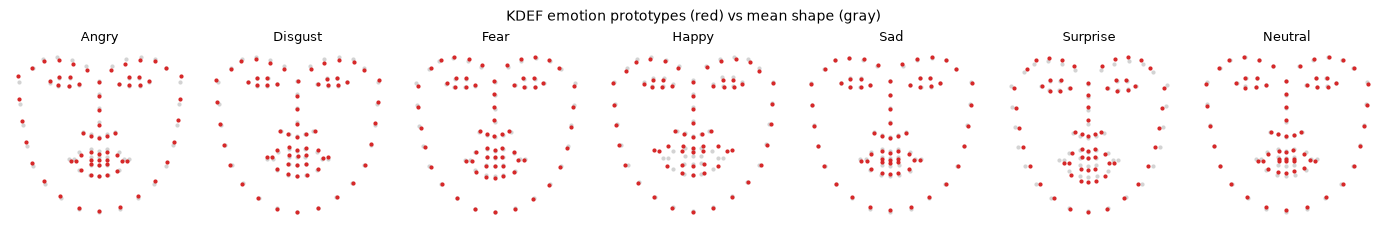

FER train classified by the nearest KDEF prototype alone: {'acc': 0.292, 'bal_acc': 0.258, 'macro_f1': 0.26}


  C1  no prototypes                val F1=0.594  n=28709 d=1056  (57s)


  C1  + prototype distances        val F1=0.594  n=28709 d=1063  (59s)
  → kept current configuration (val F1 0.594)


In [8]:
fig, axes = plt.subplots(1, 7, figsize=(14, 2.3))
for ax, c in zip(axes, range(7)):
    ax.scatter(MEAN_SHAPE[:, 0], -MEAN_SHAPE[:, 1], s=4, c="lightgray")
    ax.scatter(PROTOTYPES[c][:, 0], -PROTOTYPES[c][:, 1], s=4, c="C3")
    ax.set_title(EMO[c], fontsize=9); ax.axis("off"); ax.set_aspect("equal")
fig.suptitle("KDEF emotion prototypes (red) vs mean shape (gray)", fontsize=10)
fig.tight_layout(); fig.savefig(FIG_DIR / "task5_prototypes.png"); plt.show()

D_fer = F.prototype_distances(landmarks("fer_gray", "train"), MEAN_SHAPE, PROTOTYPES)
proto_acc = metrics(y_tr_full, D_fer.argmin(1))
print("FER train classified by the nearest KDEF prototype alone:", {k: round(v, 3) for k, v in proto_acc.items()})
try_group("C1", {"no prototypes": {}, "+ prototype distances": {"blocks": [b for b in CFG["blocks"] if b != "proto"] + ["proto"]}})

## C2: data curation and label verification
* **Duplicates / blanks:** identical images (dHash) are kept once; when copies disagree on the
  label, all copies are dropped. Near-blank images (pixel std < 3) are dropped.
* **Label verification:** a 3-fold cross-validated logistic regression gives an out-of-fold
  prediction for every training image. An image is flagged when the model predicts another
  emotion with probability > 0.6 **and** the nearest KDEF prototype agrees with the model rather
  than with the label (two independent witnesses).
Only the training set is curated; validation and test are untouched.

curation: 1347 duplicate copies, 161 images in label-conflicting groups, 12 blank → 1407 dropped


,flagged,train size,% flagged
Angry,178,3995,4.5
Disgust,10,436,2.3
Fear,275,4097,6.7
Happy,81,7215,1.1
Sad,189,4830,3.9
Surprise,120,3171,3.8
Neutral,138,4965,2.8


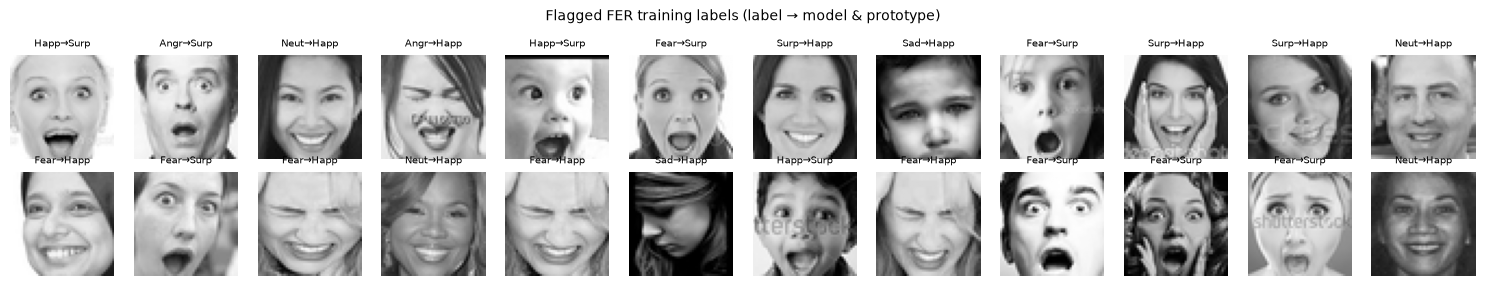

  C2  no curation                  val F1=0.594  n=28709 d=1056  (58s)


  C2  dedup + blanks               val F1=0.589  n=27302 d=1056  (54s)


  C2  dedup + blanks + flagged labels val F1=0.577  n=26353 d=1056  (48s)
  → kept current configuration (val F1 0.594)


In [9]:
X_tr_img = images("fer_gray", "train")[0]
h = F.dhash(X_tr_img)
dfh = pd.DataFrame({"h": h, "y": y_tr_full, "i": np.arange(len(h))})
conflict = dfh.groupby("h").y.transform("nunique") > 1
dup_later = dfh.duplicated("h", keep="first")
blank = X_tr_img.reshape(len(X_tr_img), -1).std(1) < 3
DROP_DEDUP = np.where(conflict | dup_later | blank)[0]
print(f"curation: {int(dup_later.sum())} duplicate copies, {int(conflict.sum())} images in label-conflicting groups, "
      f"{int(blank.sum())} blank → {len(DROP_DEDUP)} dropped")

X_lr = features("fer_gray", "train", "HOG+LM")
oof = cross_val_predict(Pipeline([("s", StandardScaler()), ("lr", LogisticRegression(max_iter=2000, C=0.1))]),
                        X_lr, y_tr_full, cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                        method="predict_proba", n_jobs=3)
pred_oof, conf_oof = oof.argmax(1), oof.max(1)
nearest_proto = D_fer.argmin(1)
FLAGGED = np.where((pred_oof != y_tr_full) & (conf_oof > 0.6) & (nearest_proto == pred_oof))[0]
flag_tab = pd.DataFrame({"flagged": np.bincount(y_tr_full[FLAGGED], minlength=7),
                         "train size": np.bincount(y_tr_full, minlength=7)}, index=EMO)
flag_tab["% flagged"] = 100 * flag_tab.flagged / flag_tab["train size"]
save_table(flag_tab, "task5_flagged_labels", float_format="%.1f"); display(flag_tab.round(1))
sel = FLAGGED[np.argsort(-conf_oof[FLAGGED])][:24]
show_images(X_tr_img[sel], [f"{EMO[y_tr_full[i]][:4]}→{EMO[pred_oof[i]][:4]}" for i in sel], ncols=12, size=1.25,
            suptitle="Flagged FER training labels (label → model & prototype)", fname="task5_flagged_examples.png")

try_group("C2", {"no curation": {"curation": "none"}, "dedup + blanks": {"curation": "dedup"},
                 "dedup + blanks + flagged labels": {"curation": "dedup+flags"}})

## D: merging FER and KDEF (paper's strategy)
The KDEF training subjects (never the 14 test subjects) are added to the FER training data,
either clean or degraded to look like FER images. With class weighting the weight of class
*c* is N/(K·n_c) — the paper's inverse-frequency weighting up to a constant. Rows also report the
KDEF test score: a merged model should work on **both** domains.

In [10]:
try_group("D", {"FER only": {"merge": "none"}, "+ KDEF (clean)": {"merge": "kdef"},
                "+ KDEF (degraded to FER-like)": {"merge": "kdef_degraded"}})

  D   FER only                     val F1=0.594  n=28709 d=1056  (58s)


  D   + KDEF (clean)               val F1=0.593  n=29493 d=1056  (60s)


  D   + KDEF (degraded to FER-like) val F1=0.593  n=29493 d=1056  (61s)
  → kept current configuration (val F1 0.594)


## E1: LBP texture features
Local Binary Patterns (uniform, P=8, R=1) histograms on a 6×6 grid (360 dims) describe the skin
texture — wrinkles around the eyes (Happy), nose wrinkling (Disgust), furrows between the brows
(Angry), visible teeth — which HOG at 8-px cells and the geometry only partly capture.

In [11]:
try_group("E1", {"no LBP": {}, "+ LBP texture": {"blocks": [b for b in CFG["blocks"] if b != "lbp"] + ["lbp"]}})

  E1  no LBP                       val F1=0.594  n=28709 d=1056  (57s)


  E1  + LBP texture                val F1=0.590  n=28709 d=1416  (69s)
  → kept current configuration (val F1 0.594)


## A4–A5: feature selection and final hyper-parameter tuning

In [12]:
try_group("A4", {"no selection": {"select": "none"}, "SelectKBest (50 %)": {"select": "kbest"}, "PCA (95 % var.)": {"select": "pca95"}})

if MODEL == "SVM":
    C0, g0 = CFG["params"].get("clf__C", 1), CFG["params"].get("clf__gamma_mult", 1.0)
    opts = {f"C={C:g}, gamma x{g:.2g}": {"params": {**CFG["params"], "clf__C": C, "clf__gamma_mult": g}}
            for C in (C0 / 2, C0, C0 * 2) for g in (g0 / 1.5, g0, g0 * 1.5)}
elif MODEL == "LR":
    opts = {f"C={C}": {"params": {**CFG["params"], "clf__C": C}} for C in sorted({CFG["params"].get("clf__C", 1) * f for f in (0.3, 1, 3)})}
else:
    opts = {f"trees=500, max_features={mf}": {"params": {**CFG["params"], "clf__n_estimators": 500, "clf__max_features": mf}}
            for mf in ("sqrt", 0.05)}
try_group("A5", opts)

  A4  no selection                 val F1=0.594  n=28709 d=1056  (56s)


  A4  SelectKBest (50 %)           val F1=0.573  n=28709 d=1056  (51s)


  A4  PCA (95 % var.)              val F1=0.591  n=28709 d=1056  (51s)
  → kept current configuration (val F1 0.594)


  A5  C=1.5, gamma x0.67           val F1=0.530  n=28709 d=1056  (46s)


  A5  C=1.5, gamma x1              val F1=0.567  n=28709 d=1056  (50s)


...

  A5  C=3, gamma x1                val F1=0.594  n=28709 d=1056  (56s)


  A5  C=3, gamma x1.5              val F1=0.598  n=28709 d=1056  (57s)


  A5  C=6, gamma x0.67             val F1=0.585  n=28709 d=1056  (62s)


  A5  C=6, gamma x1                val F1=0.593  n=28709 d=1056  (59s)


  A5  C=6, gamma x1.5              val F1=0.598  n=28709 d=1056  (55s)
  → adopted 'C=3, gamma x1.5' (val F1 0.598)


## E2: test-time augmentation (mirrored face)
Facial expressions are (almost) left-right symmetric, so the mirrored face is an equally valid
view. Averaging the class scores of both views should reduce the variance of the prediction at no
training cost. Whether the model really treats a mirrored face as the same input is tested
right after this step.

In [13]:
try_group("E2", {"single view": {"tta": False}, "+ mirrored view (TTA)": {"tta": True}})

  E2  single view                  val F1=0.598  n=28709 d=1056  (56s)


  E2  + mirrored view (TTA)        val F1=0.492  n=28709 d=1056  (72s)
  → kept current configuration (val F1 0.598)


### Why do mirrored faces not help? A controlled experiment
Flip augmentation and TTA assume that a mirrored face is "the same" input for the model. We test this
directly on equal-size training subsets with the selected configuration: train on original or mirrored
faces and test on original or mirrored PublicTest faces. Rows also separate the validation images that
have an exact copy (dHash) in Training from the others, and compare *n* real images + their *n* mirrors
with *2n* real images.


In [ ]:
reset_results("task5_mirror")
N_MIR = 2000 if SMOKE else 12000
aug_key = make_aug_dataset("flip")
n_tr = len(y_tr_full)
mir_cfg = {**CFG, "tta": False, "aug": "none", "merge": "none", "curation": "none"}
X_aug = build_X(mir_cfg, aug_key, "train")                 # rows [0, n_tr) original, [n_tr, 2 n_tr) mirrored
X_va_o, X_va_m = build_X(mir_cfg, "fer_gray", "val")[VA], build_X(mir_cfg, make_flip_dataset(), "val")[VA]
dup_va = np.isin(F.dhash(images("fer_gray", "val")[0][VA]), F.dhash(images("fer_gray", "train")[0]))
sub = stratified_subset(y_tr_full, N_MIR)
sub2 = stratified_subset(y_tr_full, 2 * N_MIR, seed=SEED + 1)
setups = {"n original": (X_aug[sub], y_tr_full[sub]),
          "n mirrored": (X_aug[n_tr + sub], y_tr_full[sub]),
          "n original + their n mirrors": (np.vstack([X_aug[sub], X_aug[n_tr + sub]]), np.r_[y_tr_full[sub], y_tr_full[sub]]),
          "2n original": (X_aug[sub2], y_tr_full[sub2])}
for name, (Xm, ym) in setups.items():
    m = make_model(mir_cfg, Xm.shape[1]).fit(Xm, ym)
    for view, Xv in (("original", X_va_o), ("mirrored", X_va_m)):
        p = m.predict(Xv)
        for subset, mask in (("all", np.ones(len(p), bool)), ("no copy in train", ~dup_va)):
            log_result("task5_mirror", y_va[mask], p[mask], train=name, test_view=view, val_subset=subset)
mir = pd.read_csv(RESULTS_DIR / "task5_mirror.csv")
mir_tab = mir.pivot_table(index="train", columns=["val_subset", "test_view"], values="macro_f1", sort=False)
mir_tab.columns = [f"{a} / {b}" for a, b in mir_tab.columns]
save_table(mir_tab, "task5_mirror_macro_f1")
print(f"n = {N_MIR}; {int(dup_va.sum())} validation images have an exact copy in Training")
display(mir_tab.round(3))


Reading the table: a model loses several points whenever the training and test faces have opposite
orientation (original→mirrored or mirrored→original), also on the images without an exact copy in
Training, while mirrored→mirrored scores the same as original→original. So FER2013 has no left/right
bias; the RBF-SVM partly recognises a test face by its similarity to near-identical training photos
(same person, photo series or crop, not caught by the exact hash), and a mirrored face no longer
matches them. This is why TTA (E2) does not help. Flipping *does* help when it adds views to the same
real images (n + mirrors > n), but less than the same number of new real images (2n), and on the
full set the kernel cap leaves room for only ~4k mirrors.


## E3: score-level ensemble of complementary SVMs
Three models that look at the face differently: the selected configuration, an SVM on texture
+ geometry (LBP+LM) and an SVM on eigenfaces (PCA of the pixels). Their decision scores are
z-normalised (statistics of the validation scores) and averaged with weights chosen on PublicTest.

In [14]:
import itertools

_ = evaluate(CFG, "E3", "member: selected config")
MEMBERS = {"selected config": (CFG, dict(LAST_SCORES))}
member_cfgs = {"LBP+LM": {**CFG, "blocks": ["lbp", "lm"], "geo_idx": None, "select": "none"}}
if MODEL == "SVM":
    member_cfgs["PCA pixels"] = {**CFG, "blocks": ["pix"], "geo_idx": None, "select": "none",
                                 "params": {**CFG["params"], **t1["all_params"].get("SVM|PCA", {})}}
for name, mcfg in member_cfgs.items():
    _ = evaluate(mcfg, "E3", f"member: {name}")
    MEMBERS[name] = (mcfg, dict(LAST_SCORES))


def z(s, ref):
    return (s - ref.mean()) / (ref.std() + 1e-12)


names = list(MEMBERS)
Z_va = {n: z(MEMBERS[n][1]["val"], MEMBERS[n][1]["val"]) for n in names}
Z_te = {n: z(MEMBERS[n][1]["test"], MEMBERS[n][1]["val"]) for n in names}
best_w, best_f1 = None, -1
for w in itertools.product([1.0], *[[0, 0.25, 0.5, 0.75, 1.0]] * (len(names) - 1)):
    f1v = f1_score(y_va, sum(wi * Z_va[n] for wi, n in zip(w, names)).argmax(1), average="macro")
    if f1v > best_f1 + 1e-9:
        best_w, best_f1 = w, f1v
WEIGHTS = dict(zip(names, best_w))
label = "ensemble " + ", ".join(f"{n} x{w:g}" for n, w in WEIGHTS.items())
log_result("task5_ablation", y_va, sum(WEIGHTS[n] * Z_va[n] for n in names).argmax(1), group="E3", option=label,
           split="val", n_train=len(ABL_IDX), dims=0)
log_result("task5_ablation", y_te, sum(WEIGHTS[n] * Z_te[n] for n in names).argmax(1), group="E3", option=label,
           split="test", n_train=len(ABL_IDX), dims=0)
USE_ENSEMBLE = best_f1 > BEST_VAL + 0.002 and sum(1 for v in WEIGHTS.values() if v > 0) > 1
print("ensemble weights:", WEIGHTS, f"val F1 {best_f1:.3f} vs selected config {BEST_VAL:.3f} →",
      "ensemble adopted" if USE_ENSEMBLE else "single model kept")
if USE_ENSEMBLE:
    HISTORY.append(("E3", label, best_f1))
    FINAL_MEMBERS = [n for n in names if WEIGHTS[n] > 0]
else:
    FINAL_MEMBERS, WEIGHTS = ["selected config"], {"selected config": 1.0}

  E3  member: selected config      val F1=0.598  n=28709 d=1056  (56s)


  E3  member: LBP+LM               val F1=0.527  n=28709 d=496  (51s)


  E3  member: PCA pixels           val F1=0.483  n=28709 d=2304  (59s)
ensemble weights: {'selected config': 1.0, 'LBP+LM': 0, 'PCA pixels': 0} val F1 0.598 vs selected config 0.598 → single model kept


## Ablation table

In [15]:
ab = pd.read_csv(RESULTS_DIR / "task5_ablation.csv")
abl = ab.pivot_table(index=["group", "option"], columns="split", values="macro_f1", aggfunc="first", sort=False)
abl = abl.reindex(columns=[c for c in ["val", "test", "kdef_test"] if c in abl.columns])
abl.columns = [f"macro-F1 {c}" for c in abl.columns]
save_table(abl, "task5_ablation_macro_f1"); display(abl.round(3))
print("Adopted steps:", HISTORY)
print("Final configuration:", {k: v for k, v in CFG.items() if k != "geo_idx"}, "geo_idx:", CFG["geo_idx"])
print("Final members:", FINAL_MEMBERS, "weights:", {n: WEIGHTS[n] for n in FINAL_MEMBERS})

macro-F1 val  \
group option                                                             
base  Task 1 best (SVM/HOG+LM)                                   0.587   
A0    gray                                                       0.587   
      CLAHE                                                      0.581   
A1    HOG o9 c8                                                  0.587   
      HOG o9 c6                                                  0.578   
      HOG o12 c8                                                 0.586   
      HOG o12 c6                                                 0.571   
A2    no balancing                                               0.587   
      class weights                                              0.586   
      SMOTE                                                      0.539   
A3    no augmentation                                            0.587   
      flip                                                       0.542   
      flip + rotation                                            0.552   
B     no geometric                                               0.587   
      + all 20 geometric                                         0.594   
      + 10 KDEF-selected geometric                               0.590   
C1    no prototypes                                              0.594   
      + prototype distances                                      0.594   
C2    no curation                                                0.594   
      dedup + blanks                                             0.589   
      dedup + blanks + flagged labels                            0.577   
D     FER only                                                   0.594   
      + KDEF (clean)                                             0.593   
      + KDEF (degraded to FER-like)                              0.593   
E1    no LBP                                                     0.594   
      + LBP texture                                              0.590   
A4    no selection                                               0.594   
      SelectKBest (50 %)                                         0.573   
      PCA (95 % var.)                                            0.590   
A5    C=1.5, gamma x0.67                                         0.530   
      C=1.5, gamma x1                                            0.567   
      C=1.5, gamma x1.5                                          0.585   
      C=3, gamma x0.67                                           0.578   
      C=3, gamma x1                                              0.594   
      C=3, gamma x1.5                                            0.598   
      C=6, gamma x0.67                                           0.585   
      C=6, gamma x1                                              0.593   
      C=6, gamma x1.5                                            0.598   
E2    single view                                                0.598   
      + mirrored view (TTA)                                      0.492   
E3    member: selected config                                    0.598   
      member: LBP+LM                                             0.527   
      member: PCA pixels                                         0.483   
      ensemble selected config x1, LBP+LM x0, PCA pix...         0.598   

                                                          macro-F1 test  \
group option                                                              
base  Task 1 best (SVM/HOG+LM)                                    0.584   
A0    gray                                                        0.584   
      CLAHE                                                       0.579   
A1    HOG o9 c8                                                   0.584   
      HOG o9 c6                                                   0.573   
      HOG o12 c8                                                  0.587   
      HOG o12 c6                                     

Adopted steps: [('B', '+ all 20 geometric', 0.5935), ('A5', 'C=3, gamma x1.5', 0.5984)]
Final configuration: {'variant': 'gray', 'blocks': ['hog', 'lm', 'geo'], 'hog': {'orientations': 9, 'pixels_per_cell': (8, 8), 'cells_per_block': (2, 2)}, 'tta': False, 'curation': 'none', 'aug': 'none', 'merge': 'none', 'select': 'none', 'balance': 'none', 'params': {'clf__C': 3, 'clf__class_weight': None, 'clf__gamma_mult': 1.5}} geo_idx: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
Final members: ['selected config'] weights: {'selected config': 1.0}


## E4: final model — refit on Training + PublicTest
All choices are frozen. "Final (train only)" is the selected model/ensemble trained on Training
(validated on PublicTest above). The delivered model is the same configuration refitted on
Training + PublicTest (more data; PublicTest is no longer needed for selection). The z-normalisation
statistics of the ensemble are kept from the validation scores of the train-only members.

In [16]:
def fused(score_dict, names_, stats):
    return sum(WEIGHTS[n] * (score_dict[n] - stats[n][0]) / stats[n][1] for n in names_)


STATS = {n: (float(MEMBERS[n][1]["val"].mean()), float(MEMBERS[n][1]["val"].std() + 1e-12)) for n in FINAL_MEMBERS}
p_train_only = fused({n: MEMBERS[n][1]["test"] for n in FINAL_MEMBERS}, FINAL_MEMBERS, STATS).argmax(1)
log_result("task5_final", y_te, p_train_only, group="final", option="final (train only)", split="test",
           n_train=len(FULL_IDX), dims=0)

t = time.time()
refit, s_trval = {}, {}
for n in FINAL_MEMBERS:
    mcfg = MEMBERS[n][0]
    cap = ABL_MAX_N - len(VA) - (len(y_kd_tr) if mcfg["merge"] != "none" else 0)
    X, y = training_set(mcfg, FULL_IDX, cap)
    X = np.vstack([X, build_X(mcfg, "fer_gray", "val")[VA]])
    y = np.concatenate([y, y_va])
    refit[n] = make_model(mcfg, X.shape[1]).fit(X, y)
    s_trval[n] = cfg_scores(refit[n], mcfg, "test")
p_final = fused(s_trval, FINAL_MEMBERS, STATS).argmax(1)
log_result("task5_final", y_te, p_final, group="final", option="final (train + val)", split="test",
           n_train=len(FULL_IDX) + len(VA), dims=0)
print(f"refit on train+val in {time.time() - t:.0f}s")

bundle = {"labels": EMO, "tta": bool(CFG["tta"]), "task": "task5",
          "trained_on": "FER2013 Training + PublicTest (configuration selected on PublicTest)",
          "members": [{"name": n, "model": refit[n], "weight": WEIGHTS[n], "mean": STATS[n][0], "std": STATS[n][1],
                       "spec": {"variant": MEMBERS[n][0]["variant"], "blocks": MEMBERS[n][0]["blocks"],
                                "hog": MEMBERS[n][0]["hog"], "geo_idx": MEMBERS[n][0]["geo_idx"],
                                "proto": {"mean_shape": MEAN_SHAPE, "prototypes": PROTOTYPES}, "crop_margin": 0.0}}
                      for n in FINAL_MEMBERS]}
joblib.dump(bundle, MODEL_DIR / "final.pkl", compress=3)
print("saved models/final.pkl with members", FINAL_MEMBERS)

refit on train+val in 64s


saved models/final.pkl with members ['selected config']


,acc,bal_acc,macro_f1
model,,,
Kit baseline (RF + landmarks),0.465,0.396,0.402
Task 1 best (SVM + HOG+LM),0.590,0.563,0.584
"Last year's group 42 (SVM, landmark-filtered test set)",0.552,0.497,0.534
Creative final (Training only),0.600,0.568,0.594
"Creative final (Training + PublicTest), delivered",0.611,0.585,0.608


,Task 1 best,Creative final
Angry,0.471,0.495
Disgust,0.644,0.674
Fear,0.469,0.495
Happy,0.777,0.779
Sad,0.447,0.461
Surprise,0.745,0.784
Neutral,0.539,0.570


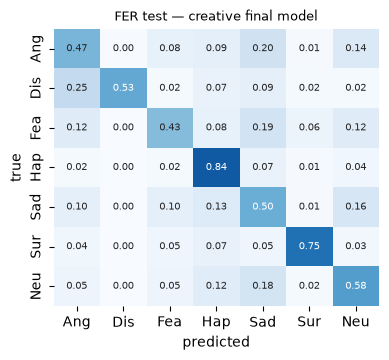

In [17]:
fin = pd.read_csv(RESULTS_DIR / "task5_final.csv").set_index("option")
t1grid = pd.read_csv(RESULTS_DIR / "task1_grid.csv")
t1b = t1grid[(t1grid.model == MODEL) & (t1grid.feature == FEAT) & (t1grid.split == "test")].iloc[0]
kit = pd.read_csv(RESULTS_DIR / "task1_baseline.csv").query("split == 'test'").iloc[0]
cols = ["acc", "bal_acc", "macro_f1"]
comparison = pd.DataFrame([
    {"model": "Kit baseline (RF + landmarks)", **kit[cols].to_dict()},
    {"model": f"Task 1 best ({MODEL} + {FEAT})", **t1b[cols].to_dict()},
    {"model": "Last year's group 42 (SVM, landmark-filtered test set)", "acc": 0.5516, "bal_acc": 0.4967, "macro_f1": 0.5344},
    {"model": "Creative final (Training only)", **fin.loc["final (train only)", cols].to_dict()},
    {"model": "Creative final (Training + PublicTest), delivered", **fin.loc["final (train + val)", cols].to_dict()},
]).set_index("model")
save_table(comparison, "task5_comparison"); display(comparison.round(3))

pcf = pd.DataFrame({"Task 1 best": pd.read_csv(RESULTS_DIR / "task1_per_class_f1.csv", index_col=0)[f"{MODEL}/{FEAT}"],
                    "Creative final": per_class_f1(y_te, p_final)})
save_table(pcf, "task5_per_class_f1"); display(pcf.round(3))
plot_cm(y_te, p_final, "FER test — creative final model"); plt.savefig(FIG_DIR / "task5_final_cm.png"); plt.show()